### Exercise 2 - Binary Classification a Straight Line Cannot Do

A - Generate the Data

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)

centers = np.array([[0., 0.], [3., 3.], [-3., -3.]])

X, c = make_blobs(
    n_samples=[500, 250, 250],
    centers=centers,
    cluster_std=1.2,
    random_state=42
)

y = (c > 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

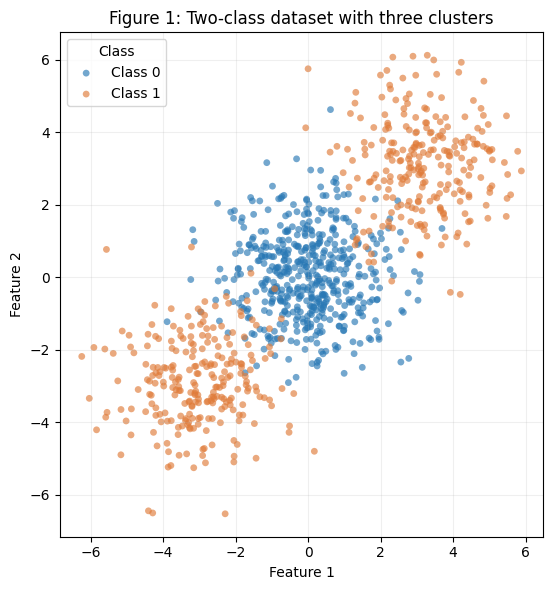

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))

for label, color in [(0, "#2878b5"), (1, "#e07b39")]:
    mask = y == label

    ax.scatter(
        X[mask, 0],
        X[mask, 1],
        color=color,
        label=f"Class {label}",
        s=24,
        alpha=0.65,
        edgecolors="none"
    )

ax.set_title("Figure 1: Two-class dataset with three clusters")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend(title="Class")
ax.grid(alpha=0.2)
ax.set_aspect("equal", adjustable="box")

fig.tight_layout()
fig.savefig("./figures/figure1.png", dpi=180)
plt.show()

| Subset | Class 0 | Class 1 | Total |
|---|---:|---:|---:|
| Full dataset | 500 | 500 | 1,000 |
| Training | 400 | 400 | 800 |
| Test | 100 | 100 | 200 |

Class 1 occupies two regions on opposite sides of Class 0, so a single straight decision boundary cannot perfectly separate the classes. This structure motivates using a hidden layer to learn a nonlinear boundary.

B - Establish the Baseline

In [18]:
from sklearn.linear_model import LogisticRegression

baseline = LogisticRegression(random_state=42)
baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

baseline_accuracy = np.mean(y_pred_baseline == y_test)

print(f"Baseline test accuracy: {baseline_accuracy:.2%}")

Baseline test accuracy: 47.50%


The baseline achieves a test accuracy of 47.50%, correctly classifying 95 of 200 test samples. 

This is below the 50% chance-level benchmark for this balanced dataset. A single linear boundary cannot capture the two outer regions of Class 1 surrounding the central region of Class 0.

C - Implement the MLP

**Forward pass and analytical gradients**

Samples are rows. With $A^{(0)}=X$, each layer computes

$$Z^{(\ell)}=A^{(\ell-1)}W^{(\ell)}+b^{(\ell)}.$$

Hidden layers use $A^{(\ell)}=\tanh(Z^{(\ell)})$. For the binary output, $P=\sigma(Z^{(L)})$, where $\sigma(z)=1/(1+e^{-z})$.

The mean binary cross-entropy over $m$ samples is

$$J=-\frac1m\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)].$$

The implemented stable form uses the output logits:

$$J=\frac1m\sum_i[\log(1+e^{z_i})-y_i z_i].$$

For each output,

$$\frac{\partial J}{\partial p_i}=\frac{p_i-y_i}{m p_i(1-p_i)},\qquad \frac{\partial p_i}{\partial z_i}=p_i(1-p_i).$$

Applying the chain rule cancels the probability factors, giving

$$\Delta^{(L)}=\frac{\partial J}{\partial Z^{(L)}}=\frac{P-Y}{m}.$$

For every layer, the weight and bias gradients are

$$\frac{\partial J}{\partial W^{(\ell)}}=(A^{(\ell-1)})^\top\Delta^{(\ell)},\qquad \frac{\partial J}{\partial b^{(\ell)}}=\sum_i\Delta_{i,:}^{(\ell)}.$$

For a preceding hidden layer, the chain rule and $\tanh'(z)=1-\tanh^2(z)$ give

$$\Delta^{(\ell-1)}=[\Delta^{(\ell)}(W^{(\ell)})^\top]\odot[1-(A^{(\ell-1)})^2].$$

Finally, gradient descent updates every layer using

$$W^{(\ell)}\leftarrow W^{(\ell)}-\eta\frac{\partial J}{\partial W^{(\ell)}},\qquad b^{(\ell)}\leftarrow b^{(\ell)}-\eta\frac{\partial J}{\partial b^{(\ell)}}.$$

All gradients are computed using the current parameters before any parameter is updated. The implementation supports arbitrary hidden-layer depth and is reused verbatim in Exercise 3.


In [19]:
class MLP:
    """Configurable MLP with tanh hidden layers."""

    def __init__(self, layer_sizes, rng, task="binary"):
        if task not in ("binary", "multiclass"):
            raise ValueError("task must be 'binary' or 'multiclass'.")

        if len(layer_sizes) < 3 or any(s < 1 for s in layer_sizes):
            raise ValueError("Use positive sizes and at least one hidden layer.")

        if task == "binary" and layer_sizes[-1] != 1:
            raise ValueError("Binary classification requires one output.")

        if task == "multiclass" and layer_sizes[-1] < 2:
            raise ValueError("Multiclass classification requires multiple outputs.")

        self.task = task
        self.n_outputs = layer_sizes[-1]
        self.weights = []
        self.biases = []

        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            limit = np.sqrt(6.0 / (n_in + n_out))
            self.weights.append(
                rng.uniform(-limit, limit, size=(n_in, n_out))
            )
            self.biases.append(np.zeros((1, n_out)))

    def output_activation(self, logits):
        if self.task == "binary":
            return np.exp(-np.logaddexp(0.0, -logits))

        shifted = logits - np.max(logits, axis=1, keepdims=True)
        exp_values = np.exp(shifted)
        return exp_values / np.sum(exp_values, axis=1, keepdims=True)

    def encode_targets(self, y):
        if self.task == "binary":
            return np.asarray(y).reshape(-1, 1)

        # Integer labels 0, ..., K-1 become one-hot rows.
        labels = np.asarray(y, dtype=int).ravel()
        return np.eye(self.n_outputs)[labels]

    def forward(self, X):
        activations = [X]

        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            z = activations[-1] @ W + b
            activations.append(np.tanh(z))

        logits = (
            activations[-1] @ self.weights[-1] + self.biases[-1]
        )
        activations.append(self.output_activation(logits))

        return activations, logits

    def loss(self, logits, y):
        targets = self.encode_targets(y)

        if self.task == "binary":
            return float(np.mean(
                np.logaddexp(0.0, logits) - targets * logits
            ))

        # Stable log-softmax, without taking log of rounded probabilities.
        shifted = logits - np.max(logits, axis=1, keepdims=True)
        log_probs = shifted - np.log(
            np.sum(np.exp(shifted), axis=1, keepdims=True)
        )

        return float(-np.mean(np.sum(targets * log_probs, axis=1)))

    def backward(self, activations, y):
        targets = self.encode_targets(y)
        m = targets.shape[0]

        # Valid for both supported activation–loss pairs.
        delta = (activations[-1] - targets) / m

        dW = [None] * len(self.weights)
        db = [None] * len(self.biases)

        for layer in range(len(self.weights) - 1, -1, -1):
            dW[layer] = activations[layer].T @ delta
            db[layer] = np.sum(delta, axis=0, keepdims=True)

            if layer > 0:
                delta = (
                    delta @ self.weights[layer].T
                ) * (1 - activations[layer] ** 2)

        return dW, db

    def update(self, dW, db, learning_rate):
        for layer in range(len(self.weights)):
            self.weights[layer] -= learning_rate * dW[layer]
            self.biases[layer] -= learning_rate * db[layer]

    def fit(self, X, y, learning_rate=0.1, epochs=2000):
        history = []

        for _ in range(epochs):
            activations, _ = self.forward(X)
            dW, db = self.backward(activations, y)
            self.update(dW, db, learning_rate)

            _, logits = self.forward(X)
            history.append(self.loss(logits, y))

        return np.array(history)

    def predict_proba(self, X):
        activations, _ = self.forward(X)
        probabilities = activations[-1]

        if self.task == "binary":
            return probabilities.ravel()

        return probabilities

    def predict(self, X):
        probabilities = self.predict_proba(X)

        if self.task == "binary":
            return (probabilities >= 0.5).astype(int)

        return np.argmax(probabilities, axis=1)

In [20]:
layer_sizes = [2, 8, 1]
learning_rate = 0.1
epochs = 2000

model = MLP([2, 8, 1], rng, task="binary")

training_loss = model.fit(
    X_train,
    y_train,
    learning_rate=learning_rate,
    epochs=epochs
)

y_pred_mlp = model.predict(X_test)
mlp_accuracy = np.mean(y_pred_mlp == y_test)

print(f"Architecture: {layer_sizes}")
print(f"Learning rate: {learning_rate}")
print(f"Epochs: {epochs}")
print(f"Test accuracy: {mlp_accuracy:.2%}")
print(f"Final training loss: {training_loss[-1]:.6f}")

Architecture: [2, 8, 1]
Learning rate: 0.1
Epochs: 2000
Test accuracy: 92.50%
Final training loss: 0.112499


| Setting | Value |
|---|---|
| Architecture | **2 → 8 → 1** |
| Hidden activation | `tanh` |
| Output activation | Sigmoid |
| Loss | Binary cross-entropy |
| Initialization | Xavier uniform weights; zero biases |
| Optimizer | Full-batch gradient descent |
| Training samples / batch size | 800 |
| Learning rate | 0.1 |
| Epochs | 2,000 |
| Trainable parameters (weights and biases) | 33 |
| First recorded training loss (after epoch 1) | **0.752517** |
| Final training loss | **0.112499** |
| Test accuracy | **92.50% — 185/200 correct** |

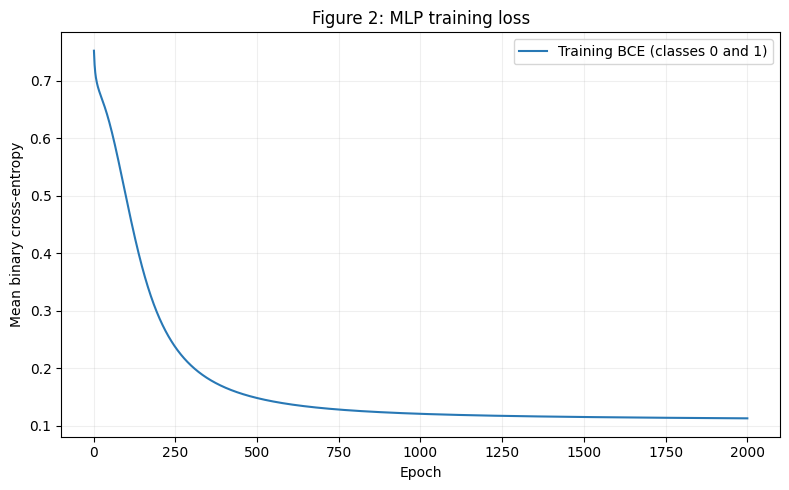

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    np.arange(1, epochs + 1),
    training_loss,
    color="#2878b5",
    label="Training BCE (classes 0 and 1)"
)

ax.set_title("Figure 2: MLP training loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean binary cross-entropy")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig("./figures/figure2.png", dpi=180)
plt.show()

The recorded training loss decreases from 0.752517 after epoch 1 to 0.112499 after epoch 2,000, with most of the improvement occurring during the earlier epochs.

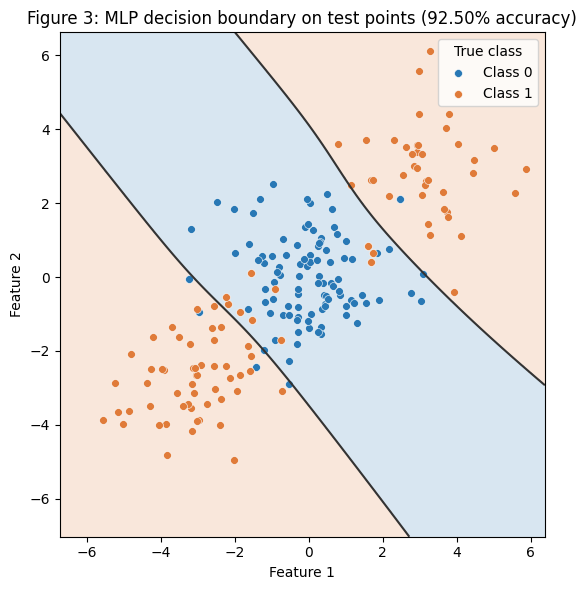

In [22]:
from matplotlib.colors import ListedColormap

# Create a grid covering the dataset's feature range.
x1 = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 350)
x2 = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 350)
xx, yy = np.meshgrid(x1, x2)

grid = np.column_stack([xx.ravel(), yy.ravel()])
probabilities = model.predict_proba(grid).reshape(xx.shape)
regions = (probabilities >= 0.5).astype(int)

fig, ax = plt.subplots(figsize=(8, 6))

# Background colors show predicted classes.
ax.contourf(
    xx, yy, regions,
    levels=[-0.5, 0.5, 1.5],
    cmap=ListedColormap(["#2878b5", "#e07b39"]),
    alpha=0.18
)

# Decision boundary: predicted probability equals 0.5.
ax.contour(
    xx, yy, probabilities,
    levels=[0.5],
    colors="#333333",
    linewidths=1.5
)

# Point colors show true test labels.
for label, color in [(0, "#2878b5"), (1, "#e07b39")]:
    mask = y_test == label
    ax.scatter(
        X_test[mask, 0],
        X_test[mask, 1],
        c=color,
        label=f"Class {label}",
        s=32,
        edgecolors="white",
        linewidths=0.4
    )

ax.set_title(
    f"Figure 3: MLP decision boundary on test points "
    f"({mlp_accuracy:.2%} accuracy)"
)
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend(title="True class")
ax.set_aspect("equal", adjustable="box")

fig.tight_layout()
fig.savefig("./figures/figure3.png", dpi=180)
plt.show()

The network learns a central region for Class 0 and two outer regions for Class 1. Most errors occur where the classes overlap.

The implementation’s analytical gradients were also checked against finite differences on a network with two hidden layers; the maximum absolute discrepancy was approximately $1.08\times10^{-11}$.

D - Analysis

The linear baseline achieves 47.50% test accuracy, while the MLP achieves 92.50%. The main reason is the geometry of the classes: Class 0 occupies the center, while Class 1 has two clusters on opposite sides.

Logistic regression produces a single straight decision boundary, assigning each class to one side of that line. It cannot place both outer clusters in Class 1 while keeping the central cluster in Class 0. Its accuracy is therefore near chance. The particular result of 47.50%, slightly below 50%, reflects the finite training and test samples; linear models are not inherently guaranteed to perform worse than guessing on this dataset.

In Figure 3, the MLP assigns Class 1 to two outer regions, toward the bottom-left and top-right, separated by a broad diagonal band assigned to Class 0. The hidden layer’s nonlinear activations allow the network to combine multiple boundaries and learn this structure. A single straight line creates only two half-planes, so it cannot produce two Class 1 regions with a Class 0 band between them.

The remaining errors occur mainly where the class distributions overlap, as visible from test points whose colors differ from the shaded regions.